# EMS Response Times Across NYC Boroughs (2021)

Do lower-income boroughs in New York City get slower or worse emergency medical service? This notebook combines three public sources:

1. **NYC EMS incident dispatch records** ([NYC Open Data](https://data.cityofnewyork.us/Public-Safety/EMS-Incident-Dispatch-Data/76xm-jjuj)): one row per call, about 25 million rows
2. **Borough median household income and poverty rate** for 2000, 2006, 2010 and 2018, scraped from the [NYU Furman Center](https://furmancenter.org/stateofthecity/view/citywide-and-borough-data)
3. **Monthly average response times to life-threatening medical emergencies** by borough ([911 Open Data, Local Law 119](https://catalog.data.gov/dataset/911-open-data-local-law-119))

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

BOROUGHS = ['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']

## Data collection and cleaning

### Borough demographics (web scraping)

This function scrapes median household income and poverty rate for each borough and saves them to `data/borough_demographics.xlsx`. The Furman Center page may have changed since this was written, so the analysis below reads the saved file instead of scraping again.

In [2]:
def scrape_borough_data(path="data/borough_demographics.xlsx"):
    import requests
    from bs4 import BeautifulSoup

    html = requests.get("https://furmancenter.org/stateofthecity/view/citywide-and-borough-data").text
    soup = BeautifulSoup(html, "html.parser")

    # Each borough has its own table; rows 10 and 11 hold median household income and poverty rate
    rows = []
    for table in soup.find_all("table"):
        for tr in table.find_all("tr")[10:12]:
            cells = [td.text.strip() for td in tr.find_all("td")]
            rows.append({cells[0]: cells[1:5]})

    data = {"New York City": rows[0:2], "The Bronx": rows[4:6], "Brooklyn": rows[6:8],
            "Manhattan": rows[8:10], "Queens": rows[10:12], "Staten Island": rows[12:14]}

    with pd.ExcelWriter(path, engine="xlsxwriter") as writer:
        for name, (med, pov) in data.items():
            df = pd.DataFrame({f"{name}: Median Household Income": med["Median household income (2019$)"],
                               "Poverty Rate": pov["Poverty rate"]},
                              index=["2000", "2006", "2010", "2018"])
            sheet = "NYC" if name == "New York City" else name.replace("The ", "")
            df.to_excel(writer, sheet_name=f"{sheet} Demographics")
    return data

### Monthly response times (JSON)

The JSON file has about 7,600 rows covering every agency and incident type. This keeps 2021 EMS rows for life-threatening medical emergencies, drops unspecified boroughs, and averages the two response-time measures (ambulance only, and ambulance plus fire) for each borough and month.

In [3]:
def response_times(path="data/nyc_data.json"):
    with open(path) as f:
        rows = [row[8:14] for row in json.load(f)["data"]]

    df = pd.DataFrame(rows, columns=["Month Name", "Agency", "Description", "Borough", "# of Incidents", "Response Times"])
    df = df[df["Month Name"].str.startswith("2021 / ")]
    df = df[df["Agency"].isin(["EMS", "Aggregate"])]
    df = df[df["Borough"] != "Unspecified"]
    df = df[df["Description"].isin([
        "Average response time to life threatening medical emergencies by ambulance units",
        "Combined average response time to life threatening medical emergencies by ambulance and fire units",
    ])]
    df[["# of Incidents", "Response Times"]] = df[["# of Incidents", "Response Times"]].astype(float)
    df = df.rename(columns={"Response Times": "Incident Response Time"})
    return (df.groupby(["Month Name", "Borough"])[["Incident Response Time", "# of Incidents"]]
              .mean().reset_index())

monthly = response_times()
print(f"{len(monthly)} borough-months")
monthly.head(10)

60 borough-months


,Month Name,Borough,Incident Response Time,# of Incidents
0,2021 / 01,Bronx,565.021531,9828.5
1,2021 / 01,Brooklyn,534.380453,11056.5
2,2021 / 01,Manhattan,548.760145,8646.0
3,2021 / 01,Queens,559.172599,8402.5
4,2021 / 01,Staten Island,547.206999,2086.0
5,2021 / 02,Bronx,601.845926,9241.5
6,2021 / 02,Brooklyn,563.873652,10193.5
7,2021 / 02,Manhattan,564.127419,8244.0
8,2021 / 02,Queens,601.199767,7824.0
9,2021 / 02,Staten Island,568.095534,1863.0


### Individual EMS calls (large CSV)

The raw dispatch file is 5.6 GB, too big to open at once, so it was split into 1-million-row chunks. The 2021 rows were taken from two of them. The filtered result is saved as `data/2021_ems_data.csv`, and the rest of the notebook loads that file. The function is kept here to show the steps; it needs the raw download to run.

**Limitation:** the filter keeps `INITIAL_SEVERITY_LEVEL_CODE >= 8`. In NYC's coding, 1 is the most severe and 8 the least, so this keeps the *least* urgent calls, and only 1,799 rows survive. Findings 2 and 3 below rest on this subset, so treat them as exploratory.

In [4]:
def clean_ems_data(chunk_a="chunk21.csv", chunk_b="chunk22.csv"):
    # 2021 starts partway through chunk 21 and ends partway through chunk 22
    data = pd.concat([pd.read_csv(chunk_a).iloc[309675:], pd.read_csv(chunk_b).iloc[:803927]])
    data = data.replace([0, 1], np.nan)

    data = data[(data["VALID_DISPATCH_RSPNS_TIME_INDC"].astype(str) == "Y") &
                (data["VALID_INCIDENT_RSPNS_TIME_INDC"].astype(str) == "Y")]
    data = data[data["INITIAL_SEVERITY_LEVEL_CODE"] >= 8]
    data = data[data["INCIDENT_DISPOSITION_CODE"].isin([82, 83, 91, 92, 94, 95, 96])]

    data = data.rename(columns={"INCIDENT_DATETIME": "Date",
                                "DISPATCH_RESPONSE_SECONDS_QY": "Dispatch Response Time",
                                "INCIDENT_RESPONSE_SECONDS_QY": "Incident Response Time",
                                "INCIDENT_DISPOSITION_CODE": "Disposition Code",
                                "BOROUGH": "Borough"})
    data = data[["Date", "Dispatch Response Time", "Incident Response Time", "Disposition Code", "Borough"]]
    data["Borough"] = data["Borough"].replace({"BRONX": "Bronx", "BROOKLYN": "Brooklyn", "MANHATTAN": "Manhattan",
                                               "QUEENS": "Queens", "RICHMOND / STATEN ISLAND": "Staten Island"})
    data = data.sort_values(["Borough", "Date"]).reset_index(drop=True)
    data.to_csv("data/2021_ems_data.csv")
    return data

ems = pd.read_csv("data/2021_ems_data.csv", index_col=0)
print(f"{len(ems)} calls")
ems["Borough"].value_counts()

1799 calls


Queens           576
Manhattan        451
Brooklyn         434
Bronx            240
Staten Island     98
Name: Borough, dtype: int64

## Findings

### 1. Estimated 2021 income and poverty by borough

The demographic data stops at 2018, so a straight-line trend through the four data points (2000, 2006, 2010, 2018) is used to estimate 2021 values. With only four points these are rough, but they're enough to rank the boroughs.

In [5]:
years = np.array([2000, 2006, 2010, 2018])
estimates = {}
for borough in BOROUGHS:
    sheet = pd.read_excel("data/borough_demographics.xlsx", sheet_name=f"{borough} Demographics")
    income_col = [c for c in sheet.columns if "Median Household Income" in c][0]
    income = pd.to_numeric(sheet[income_col].str.replace(r"[$,]", "", regex=True))
    poverty = pd.to_numeric(sheet["Poverty Rate"].str.rstrip("%"))
    estimates[borough] = {
        "2021 Median Household Income": np.polyval(np.polyfit(years, income, 1), 2021),
        "2021 Poverty Rate (%)": np.polyval(np.polyfit(years, poverty, 1), 2021),
    }

demographics = pd.DataFrame(estimates).T.sort_values("2021 Median Household Income").round(1)
demographics

,2021 Median Household Income,2021 Poverty Rate (%)
Bronx,37010.7,27.3
Brooklyn,60947.7,18.4
Queens,68164.8,11.7
Staten Island,81883.0,11.9
Manhattan,85820.2,14.4


### 2. Share of calls ending in treatment or transport (exploratory)

Calls are grouped by disposition code: 82, 91, 92, 94 and 95 count as treated or transported, and 83 and 96 as the bad outcome. Based on the subset described above.

In [6]:
treated = ems[ems["Disposition Code"].isin([82, 91, 92, 94, 95])].groupby("Borough").size()
not_treated = ems[ems["Disposition Code"].isin([83, 96])].groupby("Borough").size()

outcomes = pd.DataFrame({"Treated/Transported": treated, "Code 83 or 96": not_treated})
outcomes["Total"] = outcomes.sum(axis=1)
outcomes["% Treated/Transported"] = (outcomes["Treated/Transported"] / outcomes["Total"] * 100).round(2)
outcomes

,Treated/Transported,Code 83 or 96,Total,% Treated/Transported
Borough,,,,
Bronx,231,9,240,96.25
Brooklyn,425,9,434,97.93
Manhattan,447,4,451,99.11
Queens,571,5,576,99.13
Staten Island,96,2,98,97.96


### 3. Response time compared with what dispatch time predicts (exploratory)

A linear regression predicts incident response time from dispatch response time. A negative residual means the call was answered faster than predicted. Based on the subset described above.

In [7]:
calls = ems.dropna(subset=["Dispatch Response Time", "Incident Response Time"]).copy()
X = calls[["Dispatch Response Time"]].values
y = calls["Incident Response Time"].values
reg = LinearRegression().fit(X, y)
calls["Residual"] = y - reg.predict(X)

print(f"{len(calls)} calls with both times, R^2 = {reg.score(X, y):.3f}")

residuals = calls.groupby("Borough")["Residual"].agg(
    faster_than_predicted=lambda r: (r <= 0).sum(),
    slower_than_predicted=lambda r: (r > 0).sum(),
)
residuals["Total"] = residuals.sum(axis=1)
residuals["% faster than predicted"] = (residuals["faster_than_predicted"] / residuals["Total"] * 100).round(1)
residuals

1301 calls with both times, R^2 = 0.984


,faster_than_predicted,slower_than_predicted,Total,% faster than predicted
Borough,,,,
Bronx,166,30,196,84.7
Brooklyn,282,89,371,76.0
Manhattan,210,130,340,61.8
Queens,217,106,323,67.2
Staten Island,41,30,71,57.7


### 4. Average response time to life-threatening emergencies

From the monthly 2021 averages (12 months per borough).

In [8]:
center = (monthly.groupby("Borough")["Incident Response Time"]
                 .agg(["mean", "median"])
                 .sort_values("mean", ascending=False)
                 .round(1))
center

,mean,median
Borough,,
Bronx,607.5,603.5
Queens,594.0,590.4
Staten Island,577.2,568.2
Brooklyn,571.2,567.3
Manhattan,569.7,569.7


### 5. Month-to-month spread in response time

In [9]:
spread = (monthly.groupby("Borough")["Incident Response Time"]
                 .agg(["std", "min", "max"])
                 .sort_values("std", ascending=False)
                 .round(1))
spread

,std,min,max
Borough,,,
Bronx,32.4,565.0,662.8
Brooklyn,29.6,534.4,629.0
Queens,24.6,559.2,640.4
Staten Island,24.2,547.2,617.7
Manhattan,18.6,543.6,597.0


## Charts

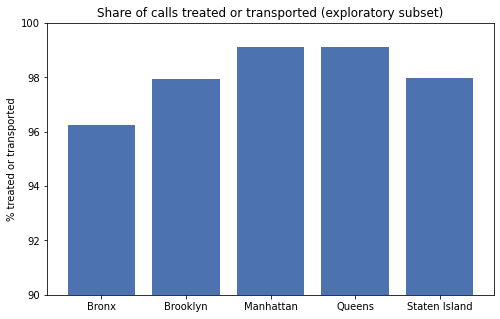

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(outcomes.index, outcomes["% Treated/Transported"], color="#4C72B0")
ax.set_ylim(90, 100)
ax.set_ylabel("% treated or transported")
ax.set_title("Share of calls treated or transported (exploratory subset)")
plt.show()

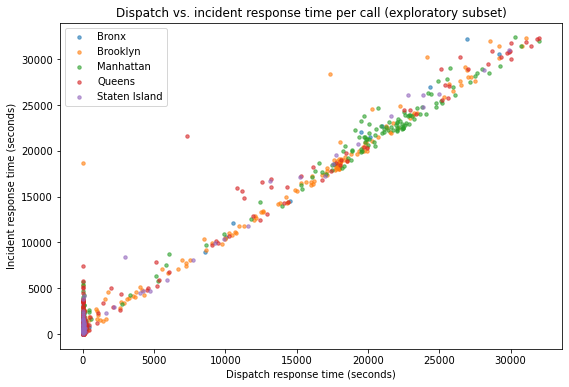

In [11]:
fig, ax = plt.subplots(figsize=(9, 6))
for borough in BOROUGHS:
    subset = calls[calls["Borough"] == borough]
    ax.scatter(subset["Dispatch Response Time"], subset["Incident Response Time"], s=12, alpha=0.6, label=borough)
ax.set_xlabel("Dispatch response time (seconds)")
ax.set_ylabel("Incident response time (seconds)")
ax.set_title("Dispatch vs. incident response time per call (exploratory subset)")
ax.legend()
plt.show()

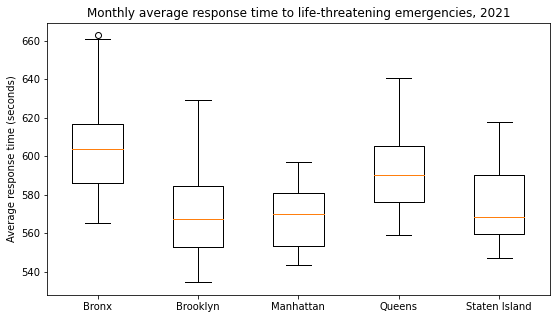

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([monthly.loc[monthly["Borough"] == b, "Incident Response Time"] for b in BOROUGHS], labels=BOROUGHS)
ax.set_ylabel("Average response time (seconds)")
ax.set_title("Monthly average response time to life-threatening emergencies, 2021")
plt.show()